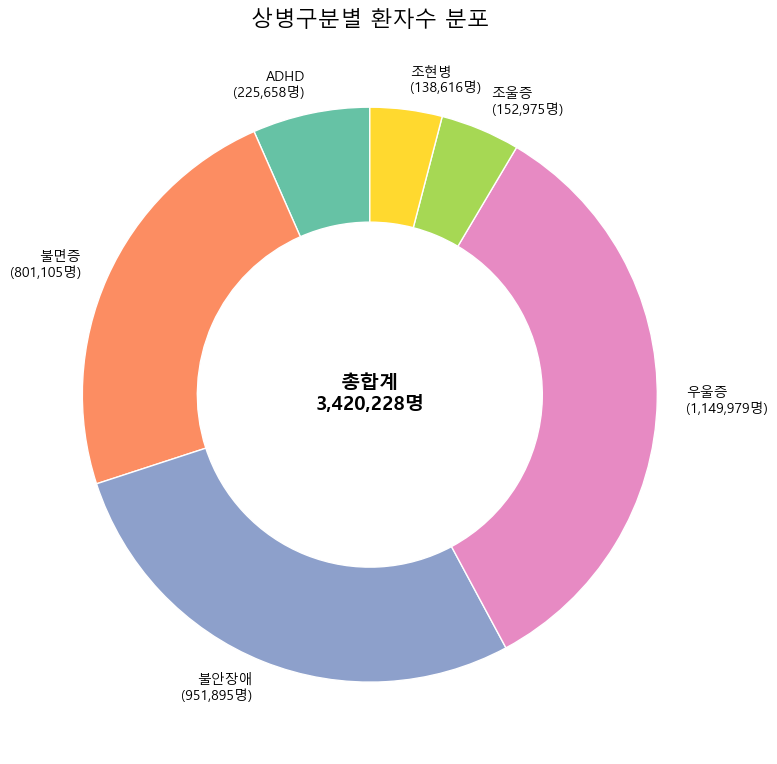

In [19]:
import matplotlib.pyplot as plt
# — 한글 폰트 설정 (Windows: 맑은고딕) —
from matplotlib import font_manager, rc
font_path = "C:/Windows/Fonts/malgun.ttf"
font_name = font_manager.FontProperties(fname=font_path).get_name()
rc('font', family=font_name)
plt.rcParams['axes.unicode_minus'] = False  # 음수 기호 깨짐 방지

# ============================================
# 1. 상병구분별 환자수 합계 데이터를 정의
# ============================================
# 예시 데이터 (피벗 테이블 결과를 수동으로 입력)
# 실제로는 앞단계에서 피벗 테이블로 구한 값을 딕셔너리나 리스트로 넣으면 됩니다.
data = {
    "상병구분": ["ADHD", "불면증", "불안장애", "우울증", "조울증", "조현병"],
    "환자수": [225658, 801105, 951895, 1149979, 152975, 138616]
}

# (선택) Pandas DataFrame으로도 만들 수 있습니다.
import pandas as pd
df_pivot = pd.DataFrame(data)

# 총합계 계산
total_patients = df_pivot["환자수"].sum()  # 3420228

# ============================================
# 2. 원형 차트 그리기
# ============================================
plt.figure(figsize=(8, 8))

# pie 차트 : labels에는 '상병구분\n(환자수)' 형태로 표시
labels = [
    f"{row['상병구분']}\n({row['환자수']:,}명)"  # 천 단위 구분 쉼표 추가
    for _, row in df_pivot.iterrows()
]

# pie 차트 그리기
wedges, texts, autotexts = plt.pie(
    df_pivot["환자수"],           # 각 조각의 크기(값)
    labels=labels,               # 조각별 라벨
    autopct="",                  # 자동 퍼센트 표시 없앰 (우리가 직접 라벨에 숫자를 넣었으므로)
    startangle=90,               # 90도에서 시작 (그래프 회전)
    pctdistance=0.75,            # 퍼센트 라벨의 반경 위치 (자동 %을 안 쓰므로 중요하지 않음)
    colors=[
        "#66c2a5", "#fc8d62", "#8da0cb", "#e78ac3", "#a6d854", "#ffd92f"
    ],  # 색상을 직접 지정 (원하는 컬러로 자유롭게 변경 가능)
    wedgeprops={"width": 0.4, "edgecolor": "w"}  # 폭을 0.4로 설정하여 도넛 형태 느낌
)

# 그래프 가운데에 총합계 텍스트 추가
plt.text(
    0, 0,                               # (x, y) 좌표: 원점(가운데)
    f"총합계\n{total_patients:,}명",    # 줄바꿈과 천 단위 쉼표
    ha="center", va="center",          # 중앙 정렬
    fontsize=14, fontweight="bold"
)

# 제목 설정
plt.title("상병구분별 환자수 분포", fontsize=16)

# 범례: 따로 범례가 필요하다면 아래 코드 추가
# plt.legend(wedges, df_pivot["상병구분"], title="상병구분",
#            loc="center left", bbox_to_anchor=(1, 0, 0.5, 1))

plt.tight_layout()

import os

desktop = os.path.join(os.path.expanduser("~"), "Desktop")
plt.savefig(os.path.join(desktop, "상병구분별 환자수 분포.png"), dpi=300)

plt.show()

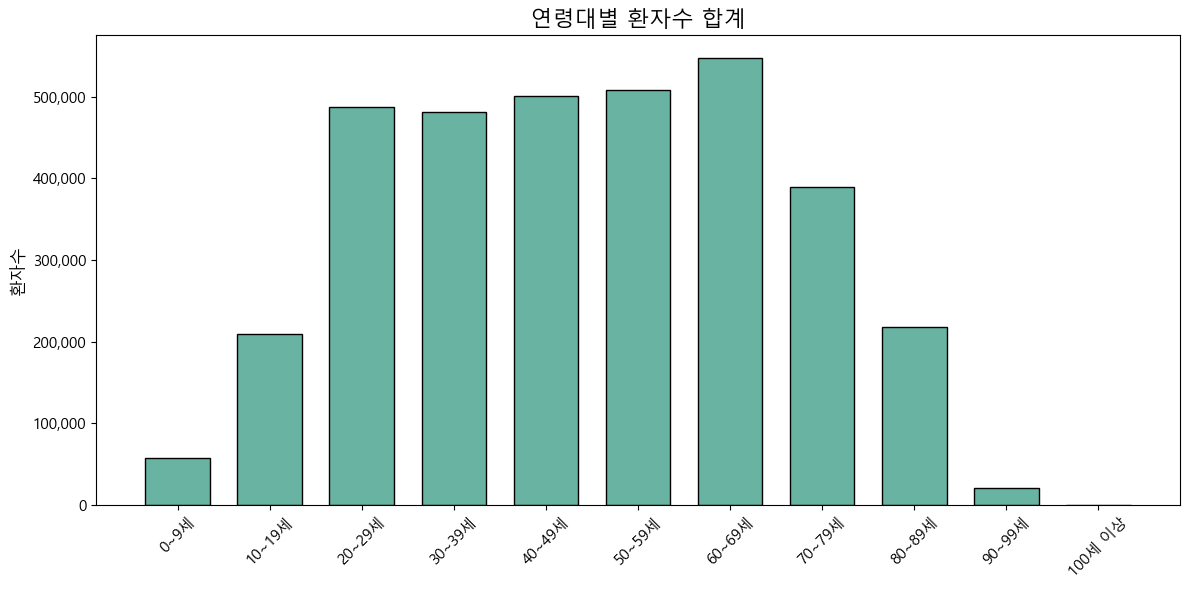

In [20]:
import pandas as pd
import matplotlib.pyplot as plt

# 연령대별 환자수 합계 데이터
age_data = {
    "연령대": [
        "0~9세", "10~19세", "20~29세", "30~39세", "40~49세",
        "50~59세", "60~69세", "70~79세", "80~89세", "90~99세", "100세 이상"
    ],
    "환자수": [
        58182, 209174, 487272, 480692, 501085,
        507838, 547637, 389659, 217404, 21275, 10
    ]
}

df_age = pd.DataFrame(age_data)

# 막대 그래프
plt.figure(figsize=(12, 6))
bars = plt.bar(
    df_age["연령대"],
    df_age["환자수"],
    color="#69b3a2",
    edgecolor="black",
    width=0.7
)

# y축 천 단위 구분 쉼표
plt.gca().yaxis.set_major_formatter(plt.FuncFormatter(lambda x, pos: f"{int(x):,}"))

plt.xticks(rotation=45, fontsize=11)
plt.yticks(fontsize=11)
plt.title("연령대별 환자수 합계", fontsize=16)
plt.ylabel("환자수", fontsize=12)


plt.tight_layout()

import os

desktop = os.path.join(os.path.expanduser("~"), "Desktop")
plt.savefig(os.path.join(desktop, "연령대별 환자수 합계.png"), dpi=300)

plt.show()

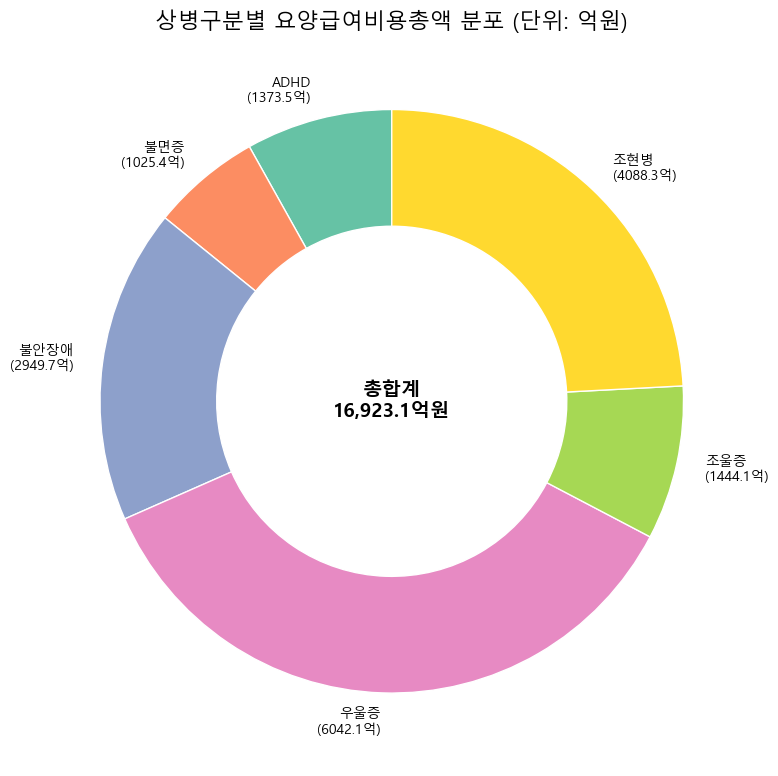

In [21]:
import pandas as pd
import matplotlib.pyplot as plt

# ============================================
# 1. 상병구분별 요양급여비용총액 데이터를 정의
# ============================================
data_cost = {
    "상병구분": ["ADHD", "불면증", "불안장애", "우울증", "조울증", "조현병"],
    "비용(원)": [1.37346e11, 1.02538e11, 2.9497e11, 6.04212e11, 1.44409e11, 4.08835e11]
}

df_cost = pd.DataFrame(data_cost)

# 단위: '억원'으로 변환 (1억원 = 1e8원)
df_cost["비용(억원)"] = df_cost["비용(원)"] / 1e8

# 총합계 계산(억원 단위)
total_cost_억원 = df_cost["비용(억원)"].sum()  # 약 16923.10

# ============================================
# 2. 원형 차트 그리기 (단위: 억원)
# ============================================
plt.figure(figsize=(8, 8))

labels = [
    f"{row['상병구분']}\n({row['비용(억원)']:.1f}억)" 
    for _, row in df_cost.iterrows()
]

wedges, texts = plt.pie(
    df_cost["비용(억원)"],
    labels=labels,
    startangle=90,
    colors=["#66c2a5", "#fc8d62", "#8da0cb", "#e78ac3", "#a6d854", "#ffd92f"],
    wedgeprops={"width": 0.4, "edgecolor": "w"}
)

plt.text(
    0, 0,
    f"총합계\n{total_cost_억원:,.1f}억원",
    ha="center", va="center", fontsize=14, fontweight="bold"
)

plt.title("상병구분별 요양급여비용총액 분포 (단위: 억원)", fontsize=16)

plt.tight_layout()

import os

desktop = os.path.join(os.path.expanduser("~"), "Desktop")
plt.savefig(os.path.join(desktop, "상병구분별 요양급여비용총액 분포.png"), dpi=300)

plt.show()

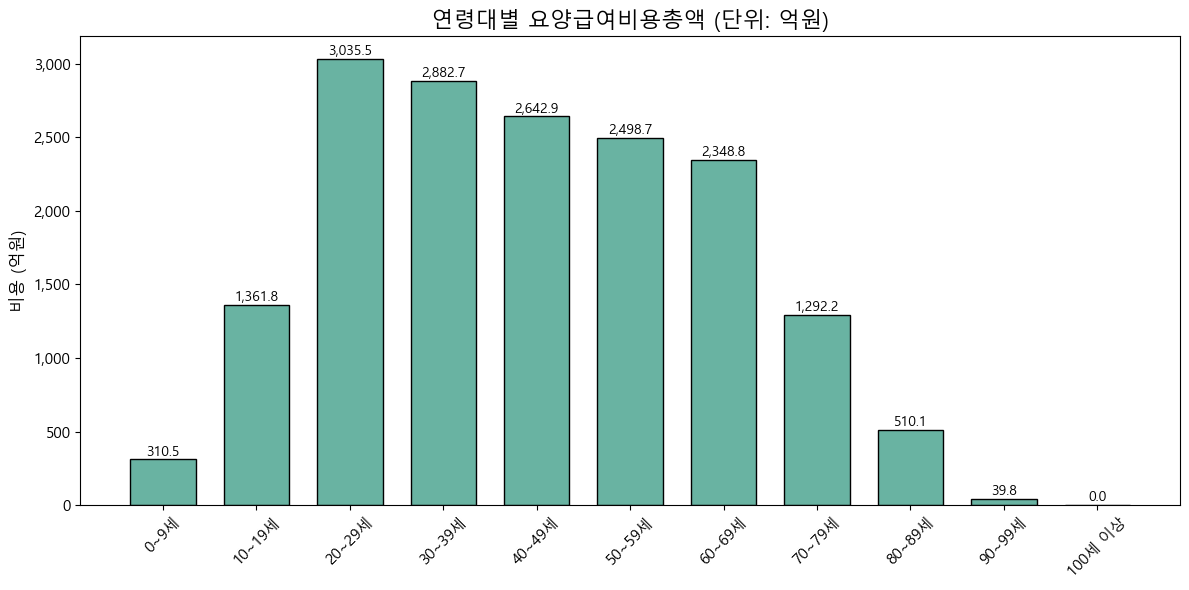

In [22]:
import pandas as pd
import matplotlib.pyplot as plt

# ==========================================
# 1. 연령대별 요양급여비용총액 데이터 정의
# ==========================================
age_cost_data = {
    "연령대": [
        "0~9세", "10~19세", "20~29세", "30~39세", "40~49세",
        "50~59세", "60~69세", "70~79세", "80~89세", "90~99세", "100세 이상"
    ],
    "비용(원)": [
        3.1048414730e10, 1.36184e11, 3.03553e11, 2.88272e11, 2.64294e11,
        2.49869e11, 2.34883e11, 1.29221e11, 5.1005635140e10, 3.978482680e9, 229610
    ]
}

df_age_cost = pd.DataFrame(age_cost_data)

# 단위: '억원'으로 변환 (1억원 = 1e8원)
df_age_cost["비용(억원)"] = df_age_cost["비용(원)"] / 1e8

# 총합계 (억원)
total_cost_age_억원 = df_age_cost["비용(억원)"].sum()

# ==========================================
# 2. 막대 그래프 그리기 (단위: 억원)
# ==========================================
plt.figure(figsize=(12, 6))
bars = plt.bar(
    df_age_cost["연령대"],
    df_age_cost["비용(억원)"],
    color="#69b3a2",
    edgecolor="black",
    width=0.7
)

# y축 천 단위 구분 쉼표
plt.gca().yaxis.set_major_formatter(plt.FuncFormatter(lambda x, pos: f"{int(x):,}"))

# 막대 위에 비용 텍스트 표시
for bar in bars:
    height = bar.get_height()
    plt.text(
        bar.get_x() + bar.get_width() / 2,    # 막대의 중앙 x 좌표
        height + 5,                           # 막대 높이 위에 표시 (5억원 위)
        f"{height:,.1f}",                     # 억원 단위, 소수 한 자리
        ha="center", va="bottom", fontsize=10
    )

plt.xticks(rotation=45, fontsize=11)
plt.yticks(fontsize=11)
plt.title("연령대별 요양급여비용총액 (단위: 억원)", fontsize=16)
plt.ylabel("비용 (억원)", fontsize=12)

plt.tight_layout()

import os

desktop = os.path.join(os.path.expanduser("~"), "Desktop")
plt.savefig(os.path.join(desktop, "연령대별 요양급여비용총액.png"), dpi=300)

plt.show()
